In [13]:
import pandas as pd
import numpy as np
import missingno as msno

In [47]:
#Criacao de dataset
df=pd.read_csv('melb_data.csv',sep=',')
df.info()
#Tamanho: 13580x21
#Muitas linhas ausentes, de menor pra maior valor ausente: Car, CouncilArea, YearBuilt, BuildingArea, concetradas principalmente em YearBuilt e BuildingArea.

<class 'pandas.DataFrame'>
RangeIndex: 13580 entries, 0 to 13579
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Suburb         13580 non-null  str    
 1   Address        13580 non-null  str    
 2   Rooms          13580 non-null  int64  
 3   Type           13580 non-null  str    
 4   Price          13580 non-null  float64
 5   Method         13580 non-null  str    
 6   SellerG        13580 non-null  str    
 7   Date           13580 non-null  str    
 8   Distance       13580 non-null  float64
 9   Postcode       13580 non-null  float64
 10  Bedroom2       13580 non-null  float64
 11  Bathroom       13580 non-null  float64
 12  Car            13518 non-null  float64
 13  Landsize       13580 non-null  float64
 14  BuildingArea   7130 non-null   float64
 15  YearBuilt      8205 non-null   float64
 16  CouncilArea    12211 non-null  str    
 17  Lattitude      13580 non-null  float64
 18  Longtitude     13

In [48]:
df_ausentes=df.isnull().sum()
resumo_ausentes=pd.DataFrame({'Quantidade_Ausentes':df_ausentes})
resumo_ausentes = resumo_ausentes[resumo_ausentes['Quantidade_Ausentes'] > 0]
resumo_ausentes = resumo_ausentes.sort_values(by='Quantidade_Ausentes', ascending=False)
resumo_ausentes

,Quantidade_Ausentes
BuildingArea,6450
YearBuilt,5375
CouncilArea,1369
Car,62


<Axes: >

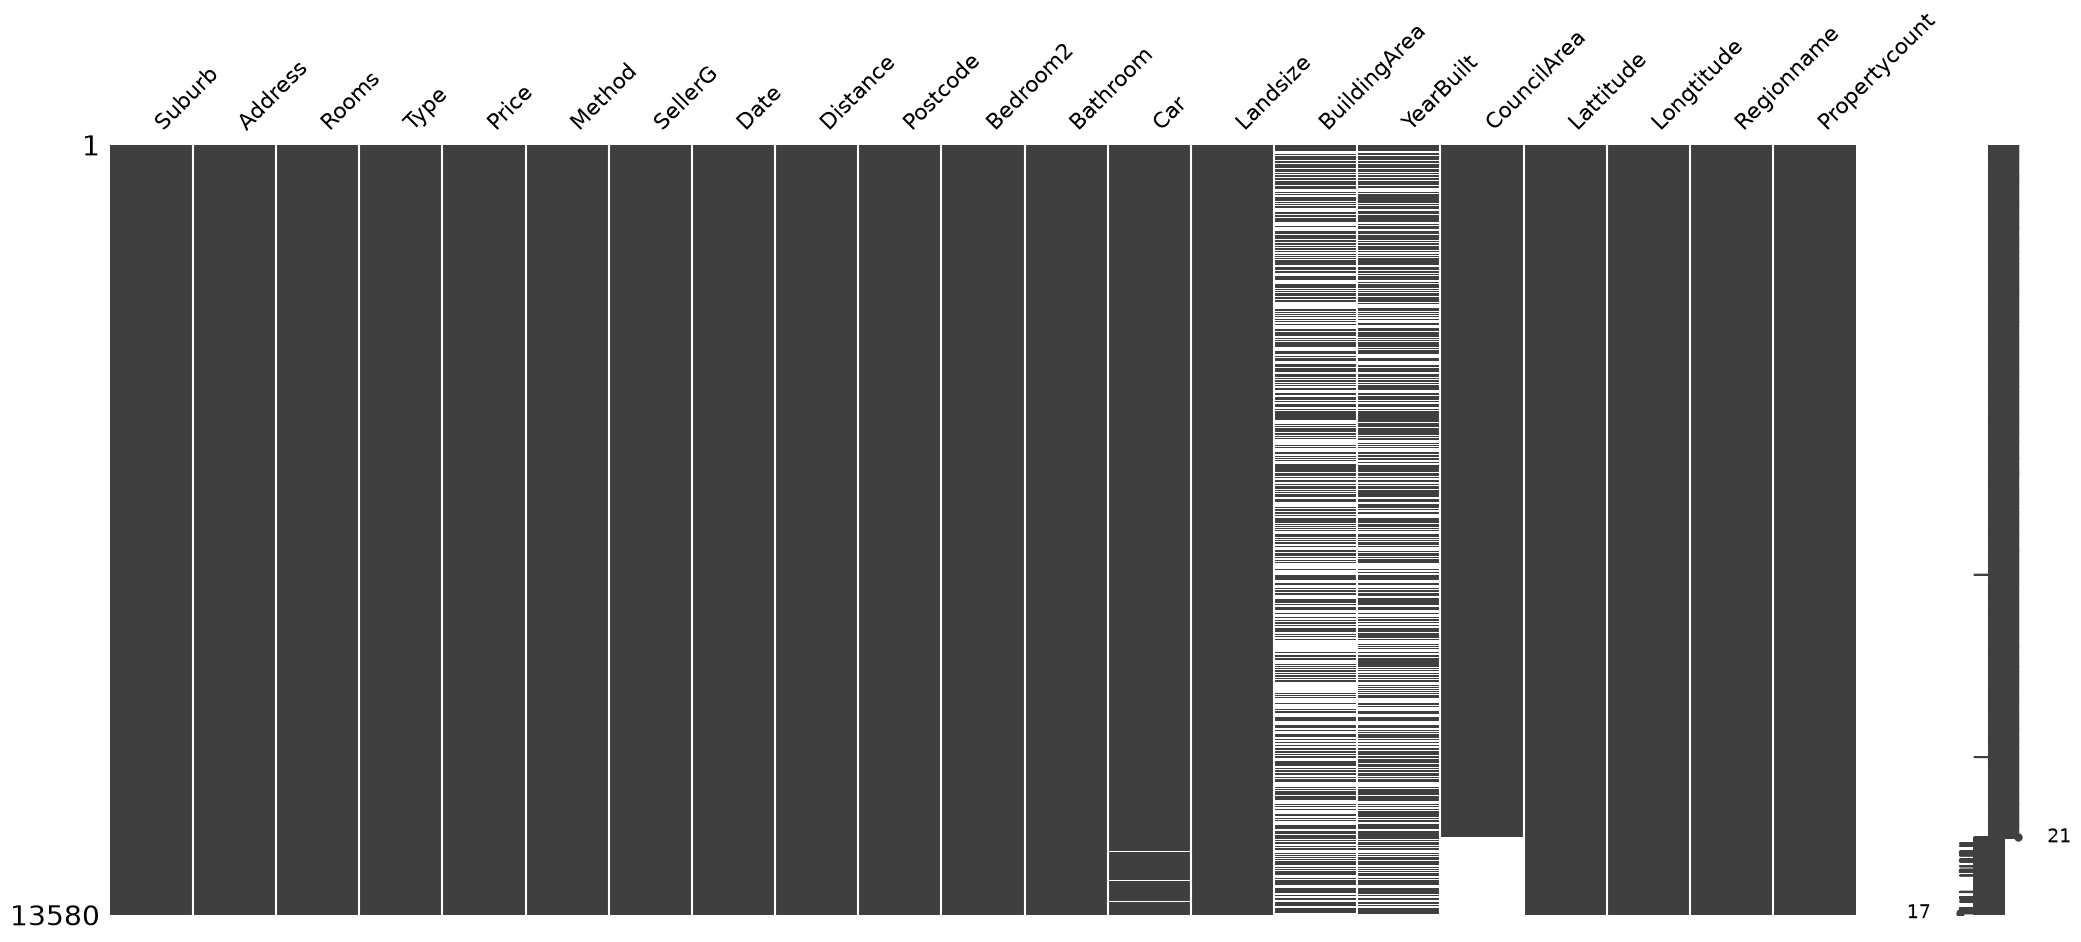

In [52]:
msno.matrix(df)
#Frequentemente parecem que ambas tem valores nulos nas mesmas linhas, mas nao é a regra, há exceçoes

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,...,1.0,0.0,156.0,79.00,1900.0,Yarra,-37.80790,144.99340,Northern Metropolitan,4019.0
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,...,2.0,0.0,134.0,150.00,1900.0,Yarra,-37.80930,144.99440,Northern Metropolitan,4019.0
4,Abbotsford,55a Park St,4,h,1600000.0,VB,Nelson,4/06/2016,2.5,3067.0,...,1.0,2.0,120.0,142.00,2014.0,Yarra,-37.80720,144.99410,Northern Metropolitan,4019.0
6,Abbotsford,124 Yarra St,3,h,1876000.0,S,Nelson,7/05/2016,2.5,3067.0,...,2.0,0.0,245.0,210.00,1910.0,Yarra,-37.80240,144.99930,Northern Metropolitan,4019.0
7,Abbotsford,98 Charles St,2,h,1636000.0,S,Nelson,8/10/2016,2.5,3067.0,...,1.0,2.0,256.0,107.00,1890.0,Yarra,-37.80600,144.99540,Northern Metropolitan,4019.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12205,Whittlesea,30 Sherwin St,3,h,601000.0,S,Ray,29/07/2017,35.5,3757.0,...,2.0,1.0,972.0,149.00,1996.0,Whittlesea,-37.51232,145.13282,Northern Victoria,2170.0
12206,Williamstown,75 Cecil St,3,h,1050000.0,VB,Williams,29/07/2017,6.8,3016.0,...,1.0,0.0,179.0,115.00,1890.0,Hobsons Bay,-37.86558,144.90474,Western Metropolitan,6380.0
12207,Williamstown,2/29 Dover Rd,1,u,385000.0,SP,Williams,29/07/2017,6.8,3016.0,...,1.0,1.0,0.0,35.64,1967.0,Hobsons Bay,-37.85588,144.89936,Western Metropolitan,6380.0
12209,Windsor,201/152 Peel St,2,u,560000.0,PI,hockingstuart,29/07/2017,4.6,3181.0,...,1.0,1.0,0.0,61.60,2012.0,Stonnington,-37.85581,144.99025,Southern Metropolitan,4380.0


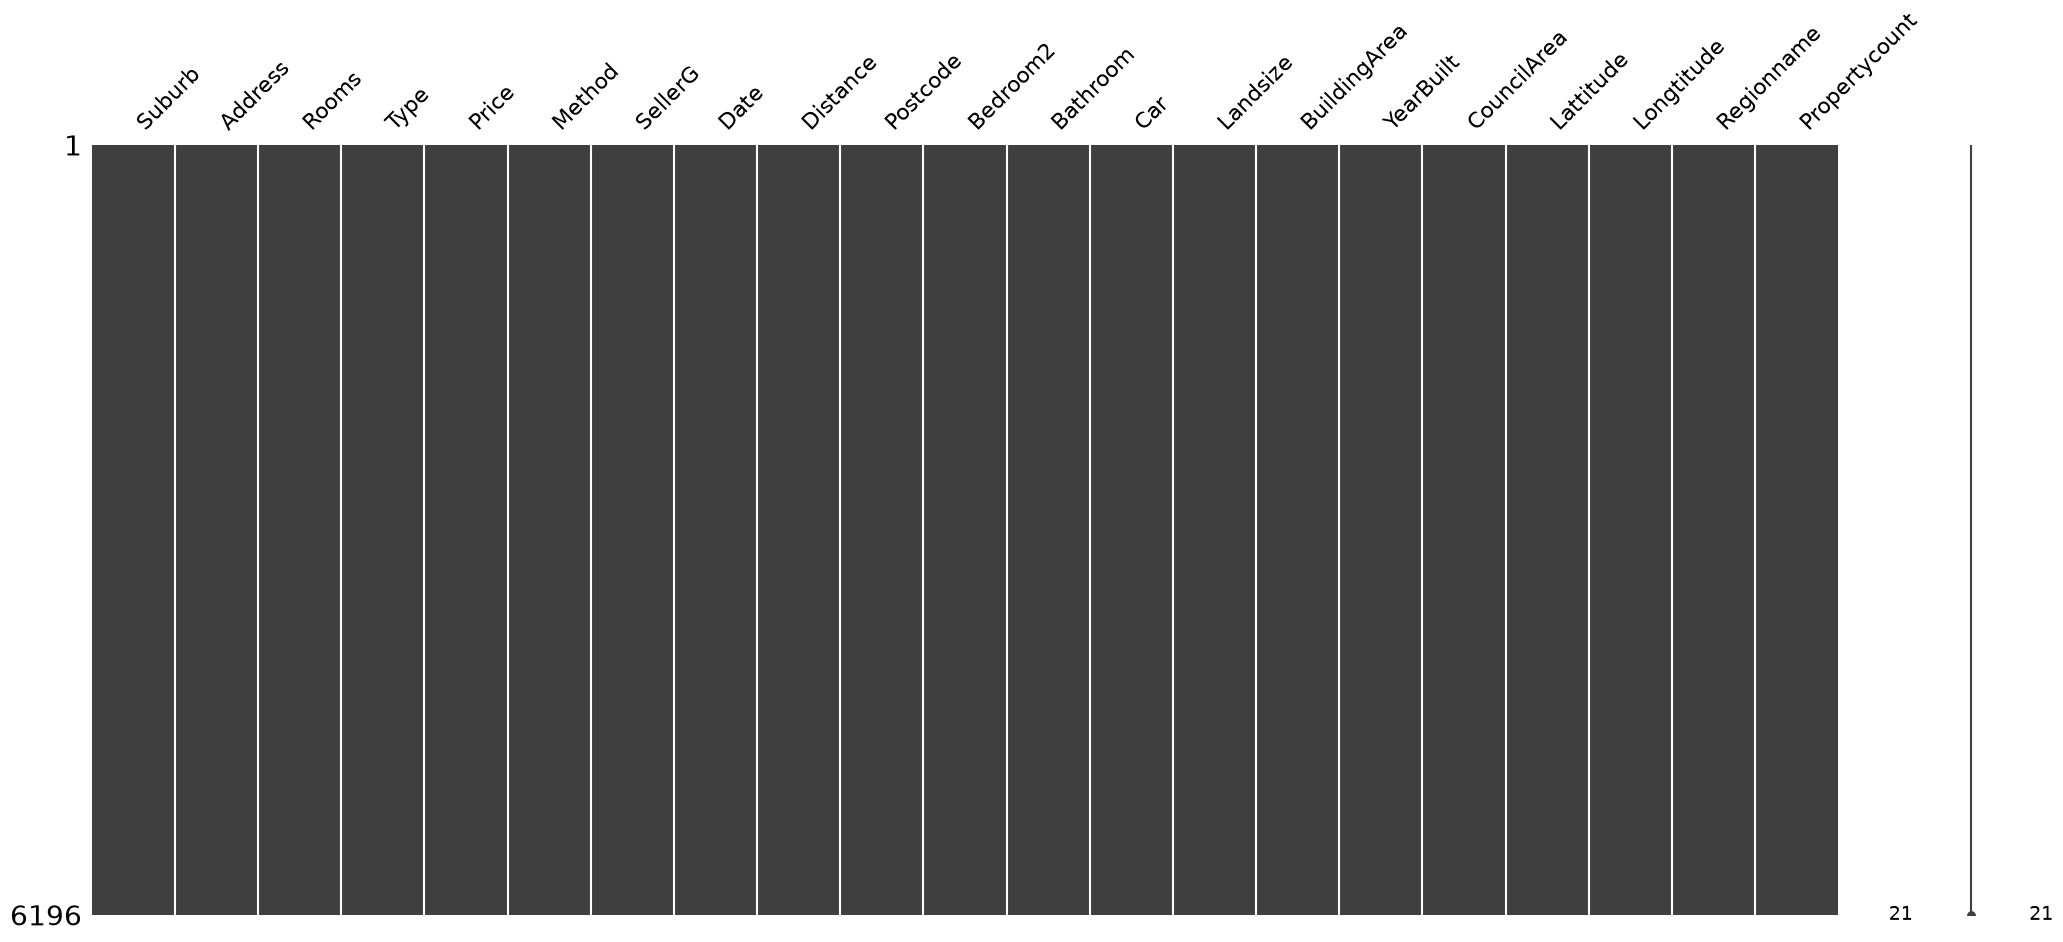

In [50]:
df_consertado_remocao=df.copy()
df_consertado_remocao=df_consertado_remocao.dropna()
msno.matrix(df_consertado_remocao)
df_consertado_remocao
#Novo tamanho: 6196x21 (7384 linhas removidas, 54.3% de TODOS os dados.)

<Axes: >

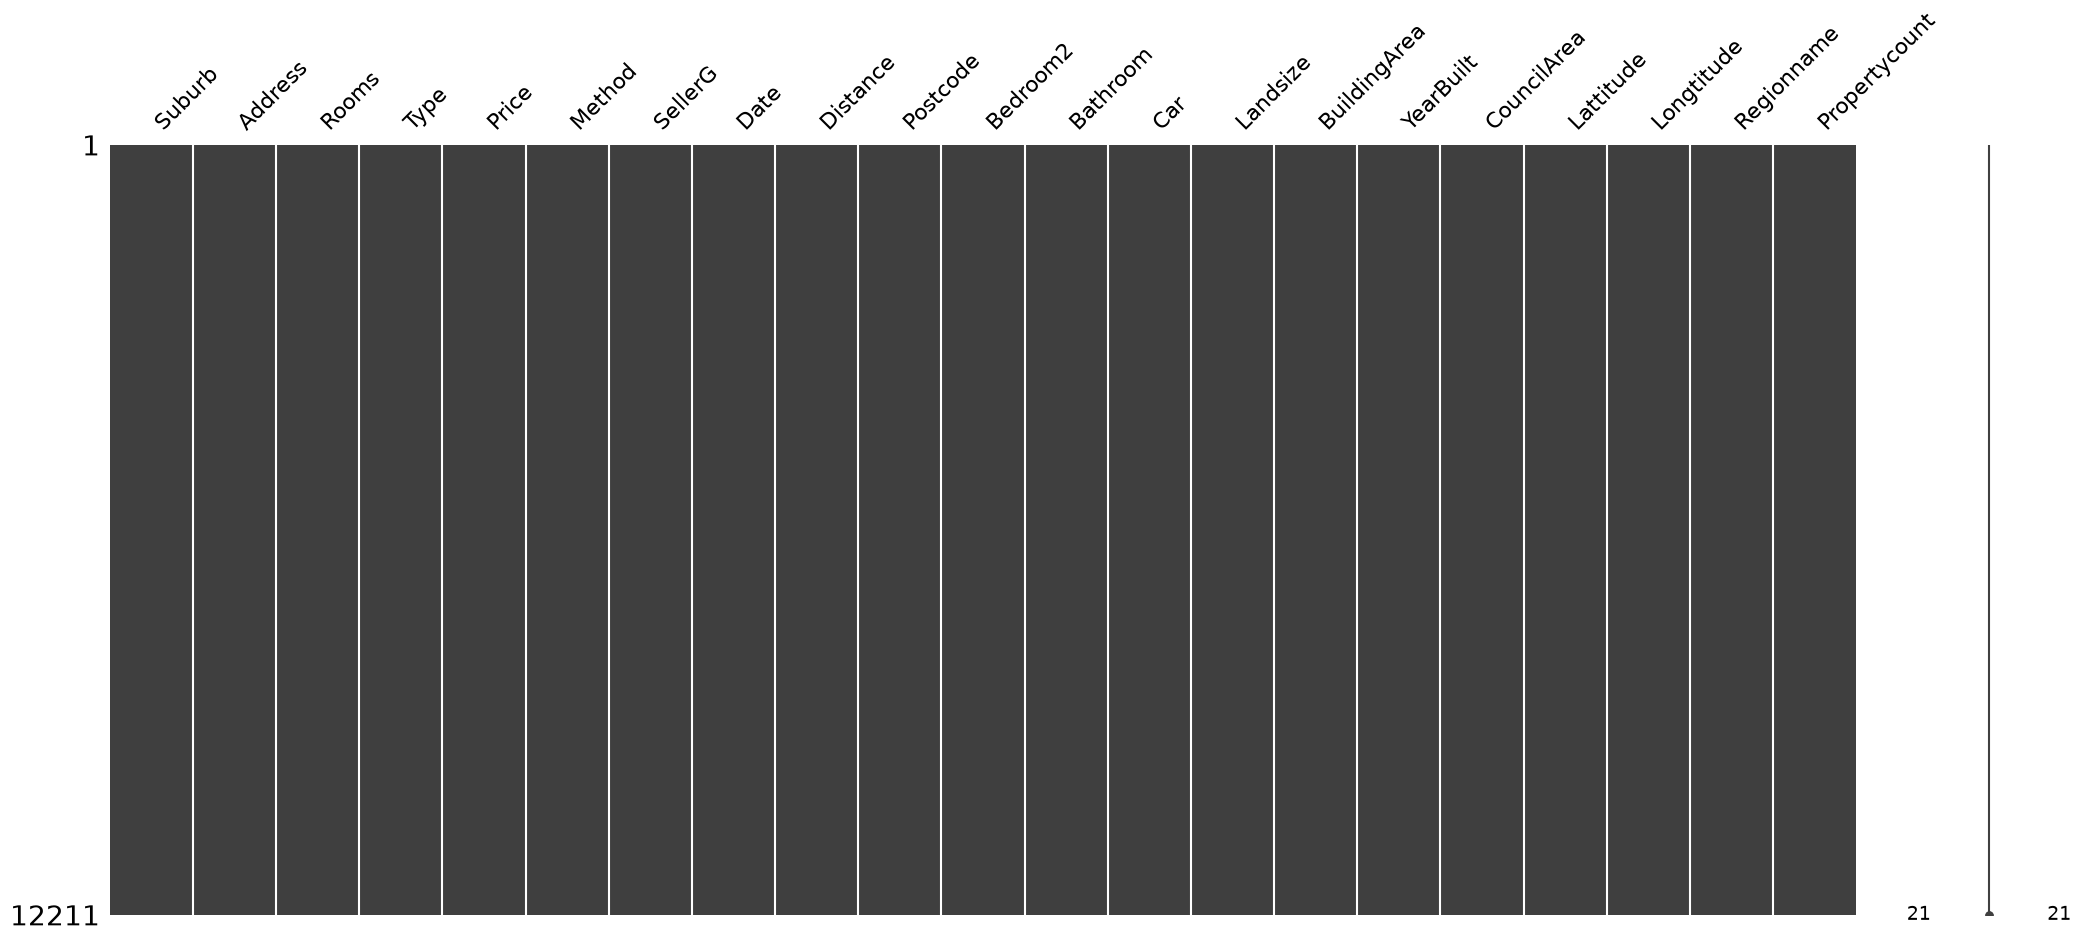

In [57]:
df_consertado_imputacao=df.copy()
median_building_area=df_consertado_imputacao['BuildingArea'].median()
df_consertado_imputacao['BuildingArea']=df_consertado_imputacao['BuildingArea'].fillna(median_building_area)
mean_year_built=df_consertado_imputacao['YearBuilt'].mean()
df_consertado_imputacao['YearBuilt']=df_consertado_imputacao['YearBuilt'].fillna(mean_year_built)
df_consertado_imputacao=df_consertado_imputacao.dropna()
msno.matrix(df_consertado_imputacao)
#